# 1 — Charger et explorer les données

### 1.a. Charger le dataset

In [1]:
import numpy as np
import pandas as pd
import tensorly as tl
import matplotlib.pyplot as plt

from tensorly.datasets.data_imports import load_covid19_serology

data = load_covid19_serology()

X = data.tensor

### 1.b. Comprendre les métadonnées

In [2]:
data.dims
data.ticks
data.tensor

array([[[-1.07613164e+00, -1.52087170e+00, -1.70474852e+00, ...,
         -2.67576987e+00, -3.42465664e+00, -1.45070875e+00],
        [-2.54476017e+00, -1.44043661e+00, -1.96465946e+00, ...,
         -1.28522688e+00, -2.95581308e+00, -1.61505247e+00],
        [-2.20397867e+00, -2.08041523e+00, -1.15232218e+00, ...,
          4.40956830e-01, -2.78715846e+00, -9.75603927e-01],
        [-1.61018952e+00, -1.56632619e+00, -2.19201704e+00, ...,
         -1.62116465e+00, -1.52032260e+00, -1.55425491e+00],
        [-3.41682210e-01, -3.54003184e-01, -3.60055582e+00, ...,
         -7.88179073e-01, -1.03480705e+00, -1.04839152e+00],
        [-1.75397339e+00, -6.62931034e-01, -2.03637809e+00, ...,
         -2.16399640e+00, -2.53454256e+00, -7.71645464e-01]],

       [[-1.21398889e+00, -1.52087170e+00, -1.49433430e+00, ...,
         -1.70698341e+00, -3.42465664e+00, -3.38495463e+00],
        [-2.54476017e+00, -1.44043661e+00, -1.59727255e+00, ...,
         -3.81150591e-01, -2.95581308e+00, -1.95377

### 1.c. Afficher les dimensions et les classes

In [3]:
print("Tensor shape:", X.shape)

print("Dimensions:", data.dims)

print("Antigens:", data.ticks[1])

print("Receptors:", data.ticks[2])

Tensor shape: (438, 6, 11)
Dimensions: ['samples', 'antigens', 'receptors']
Antigens: ['S', 'RBD', 'N', 'S1', 'S2', 'S1 Trimer']
Receptors: ['IgG1', 'IgG2', 'IgG3', 'IgA1', 'IgA2', 'IgM', 'FcRalpha', 'FcR2A', 'FcR2B', 'FcR3A', 'FcR3B']


In [4]:
from collections import Counter

print(Counter(data.ticks[0]))

Counter({'Severe': 196, 'Moderate': 122, 'Deceased': 74, 'Negative': 39, 'Mild': 7})


### 1.d. Vérifier les valeurs manquantes et l'échelle des données

In [5]:
print("Missing values:", np.isnan(X).sum())

print("Infinite values:", np.isinf(X).sum())

print("Mean:", np.mean(X))

print("Minimum:", np.min(X))

print("Maximum:", np.max(X))

Missing values: 0
Infinite values: 0
Mean: 3.146169578569698e-16
Minimum: -4.494697263217539
Maximum: 3.630143509922489


#  2 — Implémenter les opérations mathématiques de Tucker

In [6]:
def mode_n_product(X, U, n):

    # Unfolding
    X_unfolded = np.moveaxis(X, n, 0)
    X_unfolded = X_unfolded.reshape(X.shape[n], -1)

    # Matrix multiplication
    Y_unfolded = U @ X_unfolded

    # Folding
    new_shape = (U.shape[0],) + tuple(
        X.shape[i] for i in range(X.ndim) if i != n
    )

    Y = Y_unfolded.reshape(new_shape)

    Y = np.moveaxis(Y, 0, n)

    return Y

In [7]:
def tucker_reconstruct(core, factors):

    A, B, C = factors

    X_hat = mode_n_product(core, A, 0)

    X_hat = mode_n_product(X_hat, B, 1)

    X_hat = mode_n_product(X_hat, C, 2)

    return X_hat

In [8]:
# tester si mon reconstructions donnent des résultats numériquement équivalents

from tensorly.decomposition import tucker

core, factors = tucker(
    X,
    rank=[2, 3, 4],
    init='svd'
)

In [9]:
X_manual = tucker_reconstruct(core, factors)

X_tensorly = tl.tucker_to_tensor((core, factors))

print(np.allclose(X_manual, X_tensorly))

True


 # 3 — Tester plusieurs rangs multilinéaires

In [24]:
ranks_1 = [2, 4, 6, 8]

ranks_2 = [2, 3, 4]

ranks_3 = [2, 4, 6]

In [25]:
results = []

# Tester toutes les combinaisons
for r1 in ranks_1:
    for r2 in ranks_2:
        for r3 in ranks_3:

            rank = (r1, r2, r3)

            # Appliquer la décomposition de Tucker
            core, factors = tucker(
                X,
                rank=rank,
                init='svd'
            )

            # Reconstruire le tenseur
            X_hat = tl.tucker_to_tensor((core, factors))

            # Calculer l'erreur relative de reconstruction
            error = tl.norm(X - X_hat) / tl.norm(X)

            # Calculer le nombre de paramètres
            n_params = (
                r1 * r2 * r3
                + X.shape[0] * r1
                + X.shape[1] * r2
                + X.shape[2] * r3
            )

            # Enregistrer les résultats
            results.append({
                'rank': rank,
                'error': error,
                'n_params': n_params,
                'core': core,
                'factors': factors
            })

            print(
                f"Rank: {rank} | "
                f"Erreur: {error:.6f} | "
                f"Paramètres: {n_params}"
            )

Rank: (2, 2, 2) | Erreur: 0.505899 | Paramètres: 918
Rank: (2, 2, 4) | Erreur: 0.499949 | Paramètres: 948
Rank: (2, 2, 6) | Erreur: 0.499943 | Paramètres: 978
Rank: (2, 3, 2) | Erreur: 0.505715 | Paramètres: 928
Rank: (2, 3, 4) | Erreur: 0.494454 | Paramètres: 962
Rank: (2, 3, 6) | Erreur: 0.494313 | Paramètres: 996
Rank: (2, 4, 2) | Erreur: 0.505678 | Paramètres: 938
Rank: (2, 4, 4) | Erreur: 0.492244 | Paramètres: 976
Rank: (2, 4, 6) | Erreur: 0.490894 | Paramètres: 1014
Rank: (4, 2, 2) | Erreur: 0.476765 | Paramètres: 1802
Rank: (4, 2, 4) | Erreur: 0.441299 | Paramètres: 1840
Rank: (4, 2, 6) | Erreur: 0.439730 | Paramètres: 1878
Rank: (4, 3, 2) | Erreur: 0.461440 | Paramètres: 1816
Rank: (4, 3, 4) | Erreur: 0.434093 | Paramètres: 1862
Rank: (4, 3, 6) | Erreur: 0.430083 | Paramètres: 1908
Rank: (4, 4, 2) | Erreur: 0.458180 | Paramètres: 1830
Rank: (4, 4, 4) | Erreur: 0.427477 | Paramètres: 1884
Rank: (4, 4, 6) | Erreur: 0.422824 | Paramètres: 1938
Rank: (6, 2, 2) | Erreur: 0.476765 |

#### Les résultats montrent que l'augmentation des rangs de Tucker permet généralement de diminuer l'erreur relative de reconstruction, car le modèle dispose d'une capacité plus importante pour représenter les données. Cependant, cette amélioration nécessite un nombre de paramètres plus élevé. 

# 4 — les configurations (4, 2, 2), (6, 2, 2) et (8, 2, 2) ont la meme erreur : 0.476765



#### Avec la configuration (4,2,2), le cœur possède une dimension de 4 * 2 * 2 . On peut donc le représenter comme 4 petites matrices de taille 2*2 , en fixant successivement la première dimension.
#### Chaque matrice décrit les interactions entre les composantes latentes des antigènes et des récepteurs, pour une composante donnée des patients.
#### En regroupant les deux dernières dimensions, on obtient une matrice de taille r2 * r3 . Son rang effectif ne peut pas dépasser r2 * r3
#### Dans notre cas, r2 * r_3 =  4 . Ainsi, même si on augmente r1 à 6 ou 8, le modèle ne peut pas exploiter plus de 4 directions indépendantes dans le premier mode.
#### Cela explique pourquoi les configurations (4,2,2), (6,2,2) et (8,2,2) donnent pratiquement la même erreur de reconstruction.



 # 5 — Tracer l'erreur en fonction du nombre de paramètres

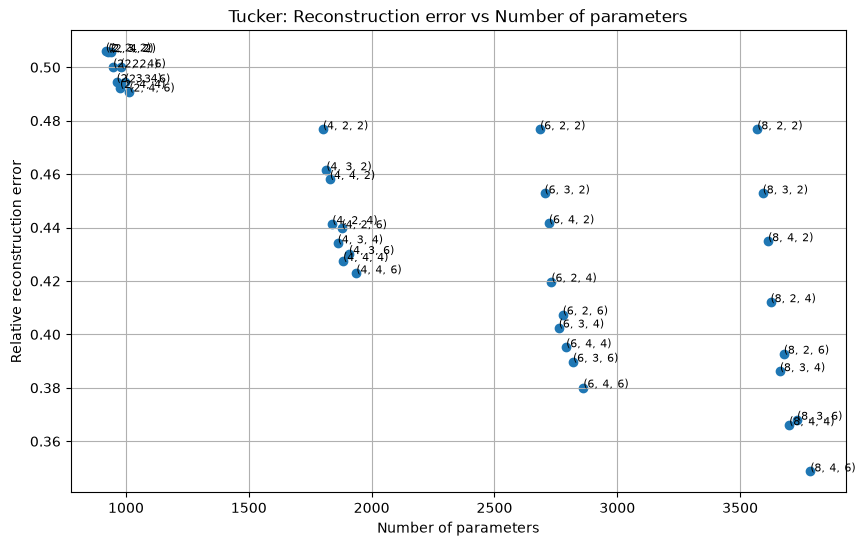

In [27]:

errors = [r['error'] for r in results]
parameters = [r['n_params'] for r in results]


plt.figure(figsize=(10, 6))

plt.scatter(parameters, errors)

for r in results:
    plt.annotate(
        str(r['rank']),
        (r['n_params'], r['error']),
        fontsize=8
    )

plt.xlabel("Number of parameters")
plt.ylabel("Relative reconstruction error")
plt.title("Tucker: Reconstruction error vs Number of parameters")

plt.grid(True)
plt.show()

## Le choix du meilleure configuration:
### le but est de ne pas juste choisir une configuration qui donne la meilleur erreur , mais de choisir une configuration qui donne le meilleur compromis entre la complexité et l'erreur.
### dans mon cas je choisi (6,4,6)

In [29]:
chosen_rank = (6, 4, 6) 

In [30]:
svd_result = next(
    r for r in results if r['rank'] == chosen_rank
)

svd_error = svd_result['error']

print("Chosen rank:", chosen_rank)
print("SVD reconstruction error:", svd_error)
print("Number of parameters:", svd_result['n_params'])

Chosen rank: (6, 4, 6)
SVD reconstruction error: 0.38008531788272565
Number of parameters: 2862


## Tester 20 initialisations aléatoires

In [31]:
random_errors = []

for seed in range(20):

    core_random, factors_random = tucker(
        X,
        rank=chosen_rank,
        init='random',
        random_state=seed
    )

    # Reconstruction
    X_random_hat = tl.tucker_to_tensor(
        (core_random, factors_random)
    )

    # Erreur relative
    error = tl.norm(X - X_random_hat) / tl.norm(X)

    random_errors.append(error)

    print(f"Seed {seed}: Error = {error:.6f}")

Seed 0: Error = 0.380070
Seed 1: Error = 0.380079
Seed 2: Error = 0.380095
Seed 3: Error = 0.380095
Seed 4: Error = 0.380068
Seed 5: Error = 0.380075
Seed 6: Error = 0.380099
Seed 7: Error = 0.380074
Seed 8: Error = 0.380093
Seed 9: Error = 0.380086
Seed 10: Error = 0.380075
Seed 11: Error = 0.380073
Seed 12: Error = 0.380077
Seed 13: Error = 0.380083
Seed 14: Error = 0.380086
Seed 15: Error = 0.380096
Seed 16: Error = 0.380082
Seed 17: Error = 0.380076
Seed 18: Error = 0.380077
Seed 19: Error = 0.380097


In [32]:
print("SVD error:", svd_error)

print("Random mean:", np.mean(random_errors))

print("Random standard deviation:", np.std(random_errors))

print("Random minimum:", np.min(random_errors))

print("Random maximum:", np.max(random_errors))

SVD error: 0.38008531788272565
Random mean: 0.3800828862979879
Random standard deviation: 9.744650063699041e-06
Random minimum: 0.3800675501965933
Random maximum: 0.38009888740014436


l'initialisation aléatiore donne presque le meme résultats , et l'eureur entre les diffirents intialisation aléatoires est 2e-5

# 6 — Visualiser et interpréter les facteurs et le tenseur cœur

In [38]:
core = svd_result['core']
factors = svd_result['factors']

A, B, C = factors

print("Core shape:", core.shape)
print("Patients factor shape:", A.shape)
print("Antigens factor shape:", B.shape)
print("Receptors factor shape:", C.shape)

Core shape: (6, 4, 6)
Patients factor shape: (438, 6)
Antigens factor shape: (6, 4)
Receptors factor shape: (11, 6)


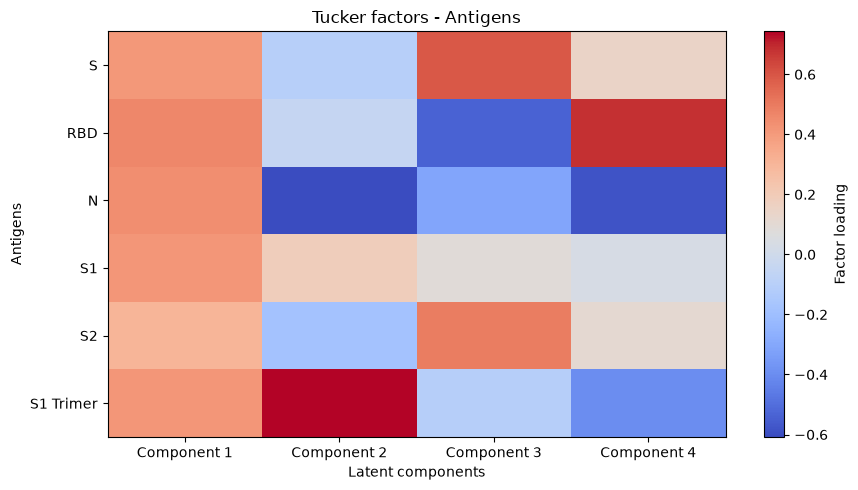

In [37]:
antigens = data.ticks[1]

plt.figure(figsize=(9, 5))

plt.imshow(B, aspect='auto', cmap='coolwarm')

plt.colorbar(label="Factor loading")

plt.xticks(
    range(B.shape[1]),
    [f"Component {i+1}" for i in range(B.shape[1])]
)

plt.yticks(range(len(antigens)), antigens)

plt.xlabel("Latent components")
plt.ylabel("Antigens")

plt.title("Tucker factors - Antigens")

plt.tight_layout()
plt.show()